## 📓 Notebook 06: Model Comparison & Evaluation

**Skills practiced:** A shared `evaluate_classifier()` function, naive-baseline accuracy, overlaid ROC curves, recall vs. accuracy tradeoffs.

**Goal:** Score all six classifiers with one consistent evaluation function and show why accuracy alone would pick a worse model than ROC-AUC or recall would.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay
import joblib

In [2]:

x_test=pd.read_csv('../data/processed/x_test_scaled.csv')
y_test=pd.read_csv("../data/processed/Y_test.csv").squeeze()
model_df=pd.read_csv('../outputs/model_scores.csv')
model_df.head()

,Unnamed: 0,Accuracy,Precision,Recall,F1,ROC AUC
0,RFC,0.662,0.316,0.632,0.421,0.709
1,LR,0.664,0.316,0.619,0.418,0.704
2,SVM,0.667,0.317,0.612,0.418,0.704
3,KNN,0.806,0.541,0.019,0.037,0.696
4,GNB,0.711,0.329,0.462,0.384,0.664


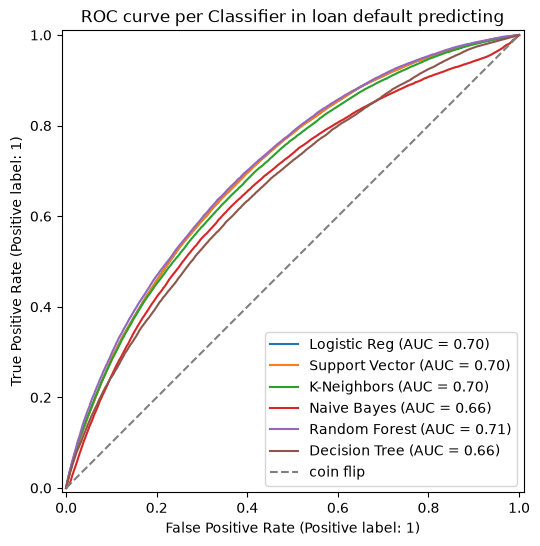

In [ ]:


fig, ax = plt.subplots(figsize=(7, 6))
MD_names = {
    "LR": "Logistic Reg",
    "SVM": "Support Vector",
    "KNN": "K-Neighbors",
    "GNB": "Naive Bayes",
    "RFC": "Random Forest",
    "DTC": "Decision Tree",
}

for name in  ["LR", "SVM", "KNN", "GNB", "RFC", "DTC"]:
    model = joblib.load(f"../models/{name}.joblib")
    RocCurveDisplay.from_estimator(model, x_test, y_test, name=MD_names[name], ax=ax)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="coin flip")
ax.legend()
plt.title('ROC curve per Classifier in loan default predicting')
plt.savefig("../outputs/figures/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()